In [26]:
# Imports
import torch
from transformers import AutoTokenizer, AutoModel

In [27]:
# Name of the model
checkpoint = "facebook/esm2_t6_8M_UR50D"

In [ ]:
### 1. Preprocessing
# Loading the tokenizer
tokenizer = AutoTokenizer.from_pretrained(checkpoint)
# Passing the sequence into the tokenizer
sequence = "CKEWMYEESSLWPCEHHDFGGQDWFFT"
# Calling the tokenizer to create the inputs
inputs = tokenizer(sequence, padding=True, truncation=True, return_tensors="pt")

In [ ]:
### 2. Passing the inputs through the model
model = AutoModel.from_pretrained(checkpoint)
with torch.no_grad():
  outputs = model(**inputs)
# 27 amino acids + 2 extra tokens = 29 tokens, 320 numbers per token
print(outputs.last_hidden_state.shape) # torch.Size([1, 29, 320])
# The pooler is random so we use last_hidden_state and not outputs.pooler_output

In [30]:
### 3. Postprocessing
# Pooling
embedding = outputs.last_hidden_state.mean(dim=1)
print(embedding.shape)

torch.Size([1, 320])


In [ ]:
# Creating the head (Postprocessing)
from torch import nn
class ScoreHead(nn.Module):
  def __init__(self):
    super().__init__()
    self.layer1 = nn.Linear(640, 128)
    self.relu = nn.ReLU()
    self.layer2 = nn.Linear(128, 1)
    self.sigmoid = nn.Sigmoid()

  def forward(self,seq_emb, target_emb):
    x = torch.cat([seq_emb, target_emb], dim = 1)
    x = self.layer1(x)
    x = self.relu(x)
    x = self.layer2(x)
    x = self.sigmoid(x)
    return x

In [ ]:
import torch
torch.manual_seed(42) # PyTorch seed: initial weights of the head
N = 200
import random
random.seed(42)      # Python seed: the 200 training sequences
amino_acids = ['A', 'R', 'N', 'D', 'C', 'Q', 'E', 'G', 'H', 'I', 'L', 'K', 'M', 'F', 'P', 'S', 'T', 'W', 'Y', 'V']
SEQ_LENGTH = 27
# 200 random sequences of 27 amino acids
sequences = ["".join(random.choices(amino_acids, k=SEQ_LENGTH)) for _ in range(N)]
hydrophobic_residues = ['A', 'I', 'L', 'M', 'F', 'W', 'Y', 'V']
fractions = [sum(1 for aa in s if aa in hydrophobic_residues) / len(s) for s in sequences]
y = torch.tensor(fractions).unsqueeze(1)
print(y.shape)

torch.Size([200, 1])


In [ ]:
# The function embed: we want an embedding for each one of the 200 sequences
def embed(sequences):
  embeddings = []
  for s in sequences:
    inputs = tokenizer(s, return_tensors="pt")
    with torch.no_grad():
      outputs = model(**inputs)
    embeddings.append(outputs.last_hidden_state.mean(dim=1))
  return torch.cat(embeddings, dim=0)

In [34]:
X = embed(sequences)
print(X.shape)

torch.Size([200, 320])


In [ ]:
# Placeholder target: an arbitrary sequence with no biological meaning.
# The labels do not depend on the target, so the head learns to ignore it.
target_sequence = "ACDEFGHIKLMNPQRSTVWYACDEFGH"
target_emb = embed([target_sequence])
target_embs = target_emb.repeat(N, 1)
print(target_embs.shape)

torch.Size([200, 320])


In [ ]:
# Split the data: 80% training, 20% test
split = round(0.8 * N)
X_train, X_test = X[:split], X[split:]
T_train, T_test = target_embs[:split], target_embs[split:]
y_train, y_test = y[:split], y[split:]

In [37]:
print(X_train.shape, X_test.shape)
print(T_train.shape, T_test.shape)
print(y_train.shape, y_test.shape)

torch.Size([160, 320]) torch.Size([40, 320])
torch.Size([160, 320]) torch.Size([40, 320])
torch.Size([160, 1]) torch.Size([40, 1])


In [ ]:
### Creating a new head
torch.manual_seed(42)
head = ScoreHead()
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(params= head.parameters(), lr=0.001)

In [ ]:
# Baseline: MSE of always predicting the mean of the training labels.
print(y_train.var().item())

0.00914920773357153


In [40]:
# The loop
epochs = 300

for epoch in range(epochs):
  head.train()

  y_pred = head(X_train, T_train)
  loss = loss_fn(y_pred, y_train)

  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

  if epoch % 20 == 0:
    head.eval()
    with torch.inference_mode():
      test_pred = head(X_test, T_test)
      test_loss = loss_fn(test_pred, y_test)
    print(f"Epoch: {epoch} | Train loss: {loss:.4f} | Test loss: {test_loss:.4f}")

Epoch: 0 | Train loss: 0.0208 | Test loss: 0.0118
Epoch: 20 | Train loss: 0.0066 | Test loss: 0.0070
Epoch: 40 | Train loss: 0.0037 | Test loss: 0.0041
Epoch: 60 | Train loss: 0.0016 | Test loss: 0.0022
Epoch: 80 | Train loss: 0.0008 | Test loss: 0.0010
Epoch: 100 | Train loss: 0.0006 | Test loss: 0.0006
Epoch: 120 | Train loss: 0.0004 | Test loss: 0.0005
Epoch: 140 | Train loss: 0.0003 | Test loss: 0.0004
Epoch: 160 | Train loss: 0.0003 | Test loss: 0.0004
Epoch: 180 | Train loss: 0.0003 | Test loss: 0.0004
Epoch: 200 | Train loss: 0.0002 | Test loss: 0.0003
Epoch: 220 | Train loss: 0.0002 | Test loss: 0.0003
Epoch: 240 | Train loss: 0.0002 | Test loss: 0.0003
Epoch: 260 | Train loss: 0.0002 | Test loss: 0.0003
Epoch: 280 | Train loss: 0.0002 | Test loss: 0.0003


In [ ]:
# Limitation check: a fully hydrophobic sequence (true fraction = 1.0)
extreme = embed(["L" * SEQ_LENGTH])
with torch.inference_mode():
    print(head(extreme, target_emb))
# The head outputs ~0.53, probably because it saw no training examples above 0.65

tensor([[0.5259]])


In [ ]:
# Saving the model
torch.save(head.state_dict(), "score_head.pth")

In [ ]:
!pip install deap

In [ ]:
# The ga.py connection
from deap import base, creator, tools
creator.create("FitnessMax", base.Fitness, weights=(1.0,))
creator.create("Individual", list, fitness=creator.FitnessMax)
toolbox = base.Toolbox()
toolbox.register("attr_amino_acid", random.choice, amino_acids)
toolbox.register("individual", tools.initRepeat, creator.Individual, toolbox.attr_amino_acid, n=SEQ_LENGTH)
toolbox.register("population", tools.initRepeat, list, toolbox.individual)
toolbox.register("mate", tools.cxOnePoint)

def mutate_amino_acid(individual, indpb):
    for i in range(len(individual)):
        if random.random() < indpb:
            individual[i] = random.choice(amino_acids)
    return individual,

toolbox.register("mutate", mutate_amino_acid, indpb=0.02)
toolbox.register("select", tools.selTournament, tournsize=3)

In [46]:
# The new fitness function
def evaluate_head(individual):
  seq = "".join(individual)
  emb = embed([seq])
  with torch.inference_mode():
    score = head(emb, target_emb)
  return (score.item(),)

In [47]:
# Setting the new fitness function
toolbox.register("evaluate", evaluate_head)

In [50]:
def true_fraction(individual):
  return sum(1 for aa in individual if aa in hydrophobic_residues) / len(individual)



In [ ]:
# The first run used random.seed(42). Change the seed and re-run the GA to reproduce it.
POP_SIZE = 100
random.seed(7)
population = toolbox.population(n=POP_SIZE)

for ind in population:
  ind.fitness.values = toolbox.evaluate(ind)

print(f"head score: {sum(ind.fitness.values[0] for ind in population) / len(population)}")
print(f"true fraction: {sum(true_fraction(ind) for ind in population) / len(population)}")

In [52]:
CXPB = 0.5
MTPB = 0.2
NGEN = 50

In [ ]:
# Run the cell that creates the population, right before this one
# otherwise the loop continues from an already evolved population.
head_history = []
true_history = []
for gen in range(NGEN):
    chosen = toolbox.select(population, len(population))
    offspring = [toolbox.clone(ind) for ind in chosen]



    for child1, child2 in zip(offspring[::2], offspring[1::2]):
        if random.random() < CXPB:
            toolbox.mate(child1, child2)
            del child1.fitness.values
            del child2.fitness.values


    for mutant in offspring:
        if random.random() < MTPB:
            toolbox.mutate(mutant)
            del mutant.fitness.values

    invalid_ind = [ind for ind in offspring if not ind.fitness.valid]
    for ind in invalid_ind:
        ind.fitness.values = toolbox.evaluate(ind)

    population[:] = offspring
    head_mean = sum(ind.fitness.values[0] for ind in population) / len(population)
    true_mean = sum(true_fraction(ind) for ind in population) / len(population)
    head_history.append(head_mean)
    true_history.append(true_mean)
    print(gen, round(head_mean, 4), round(true_mean, 4))

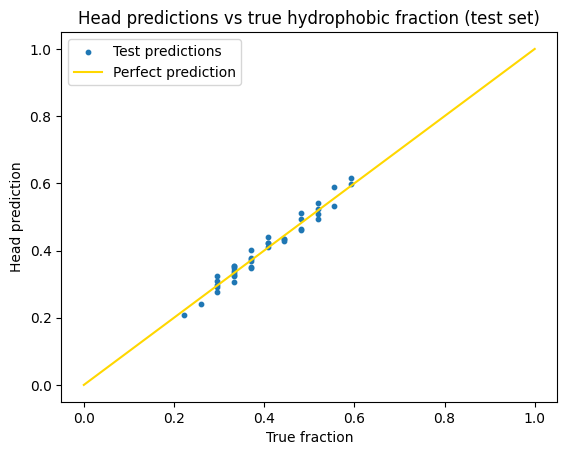

In [72]:
### Creating the diagram
# Head evaluation on the test set (40 sequences not seen during training).
# Each point is one sequence: x = true hydrophobic fraction, y = head prediction.
# The yellow line is the ideal case (prediction = true value).
# Points close to the line mean the head learned to predict the fraction
# from the ESM-2 embedding. The test data only covers ~0.2-0.6, so this
# plot says nothing about how the head behaves above that range.
head.eval()
with torch.inference_mode():
  test_preds = head(X_test, T_test)

import matplotlib.pyplot as plt

plt.scatter(y_test, test_preds, s=10, label="Test predictions")
plt.plot([0, 1], [0, 1], color= "gold", label="Perfect prediction")
plt.xlabel("True fraction")
plt.ylabel("Head prediction")
plt.legend()
plt.title("Head predictions vs true hydrophobic fraction (test set)")
plt.savefig("head_preds_vs_true_fraction.png", dpi=150)
plt.show()

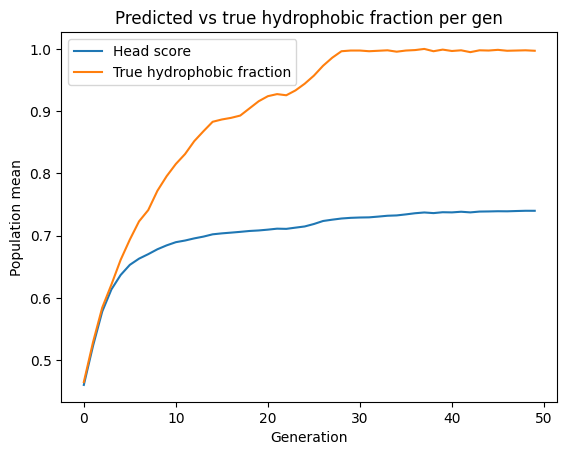

In [ ]:
### Creating another diagram
# GA run guided only by the head (fitness = head score), 50 generations.
# Blue: mean head score per generation (what the GA sees).
# Orange: mean true hydrophobic fraction, computed independently from the sequences.
# Both rise together at first, then the head score plateaus at ~0.74 because it was
# trained only on sequences up to ~0.65 hydrophobic fraction. The true fraction keeps
# rising to ~1.0 because the GA only needs the head to rank sequences correctly,
# not to predict exact values.
# Single run, so this shows the mechanism works, not that the result is robust.
generations = list(range(NGEN))
plt.plot(generations, head_history, label="Head score")
plt.plot(generations, true_history, label="True hydrophobic fraction")
plt.xlabel("Generation")
plt.ylabel("Population mean")
plt.legend()
plt.title("Predicted vs true hydrophobic fraction per gen")
plt.show()

In [ ]:
# Save the seed 42 results before re-running the GA with another seed
# The two-seed plot was made by running the GA cell twice (seed 42, then seed 7), saving the results after each run.
# Run all will not reproduce both curves.
head_history_42 = head_history.copy()
true_history_42 = true_history.copy()

In [ ]:
head_history_7 = head_history.copy()
true_history_7 = true_history.copy()

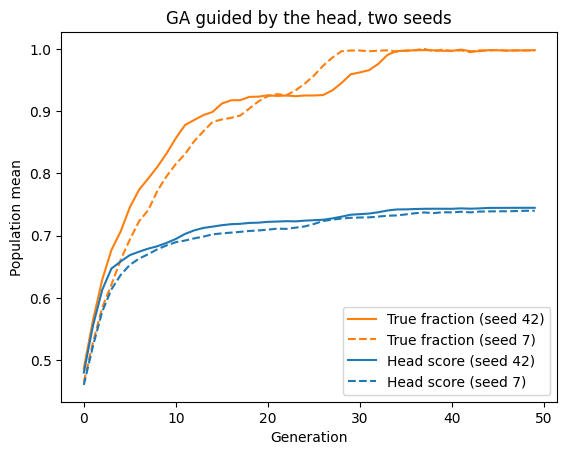

In [ ]:
# Run with two different seeds (42 and 7) to check that the result does not depend on the random starting population.
# Orange: true hydrophobic fraction (independent check). 
# Blue: head score (what the GA sees).
# In both runs the true fraction rises to ~1.0, while the head score flattens at ~0.74.
plt.plot(true_history_42, color="tab:orange", label="True fraction (seed 42)")
plt.plot(true_history_7, color="tab:orange", linestyle="--", label="True fraction (seed 7)")
plt.plot(head_history_42, color="tab:blue", label="Head score (seed 42)")
plt.plot(head_history_7, color="tab:blue", linestyle="--", label="Head score (seed 7)")
plt.xlabel("Generation")
plt.ylabel("Population mean")
plt.title("GA guided by the head, two seeds")
plt.legend()
plt.savefig("ga_two_seeds.png", dpi=150)
plt.show()